# Analisis exploratorio

Antes de modelar el traslado quiero ver como se comportan las series: si hay regimenes de inflacion, si conviene trabajar en niveles o en variaciones, que tan juntos se mueven el mayorista y la gondola, cuanta estacionalidad hay y que pasa entre regiones.

Lee lo que arma dbt en `dbt/monitor.duckdb` (hay que correr `uv run dbt build` antes). Gondola es el IPC y mayorista el IPIM. Cuando no aclaro region, la gondola es GBA.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from monitor import analisis as a

a.estilo()
con = a.conectar()
precios = a.cargar_precios(con)
general = a.inflacion_general(con)
nombres = a.nombres_rubros(con)

desde, hasta = precios.fecha.min(), precios.fecha.max()
print(f"{precios.par_id.nunique()} rubros, de {desde:%m-%Y} a {hasta:%m-%Y}")

19 rubros, de 12-2015 a 10-2026


## 1. Inflacion general

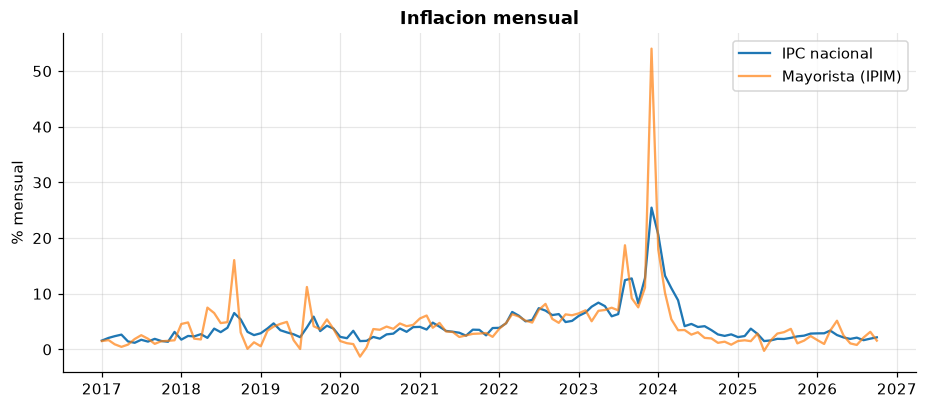

region,Nacional,mayorista
fecha,,
2017,1.9,1.5
2018,3.3,4.8
2019,3.7,3.9
2020,2.6,2.6
2021,3.5,3.5
2022,5.7,5.7
2023,10.0,12.3
2024,6.8,4.5
2025,2.3,2.0


In [2]:
mensual = (np.expm1(general[["Nacional", "mayorista"]]) * 100).dropna()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(mensual.index, mensual["Nacional"], label="IPC nacional")
ax.plot(mensual.index, mensual["mayorista"], label="Mayorista (IPIM)", alpha=0.7)
ax.set_ylabel("% mensual")
ax.set_title("Inflacion mensual")
ax.legend()
plt.show()

mensual.groupby(mensual.index.year).mean().round(1)

- Se ven tres etapas: cerca del 2% mensual (2017 y 2025-2026), entre 3 y 4% (2018-2021) y muy alta en 2022-2024, con el pico en diciembre de 2023.
- El mayorista es bastante mas volatil. En los meses de saltos fuertes (sep-2018, ago-2019, ago y dic-2023) se dispara mucho mas que la gondola y despues la gondola lo va alcanzando.
- Con etapas tan distintas, un solo numero de traslado para todo el periodo puede mezclar cosas. En la fase 4 hay que probar por regimen.

## 2. Niveles o variaciones

ADF parte de que la serie no es estacionaria y KPSS de que si. Tomo una serie como estacionaria solo si los dos coinciden.

In [3]:
estac = a.resumen_estacionariedad(precios)
estac.groupby("transf")["estacionaria"].mean().rename("% estacionarias").mul(100).round()

transf
log nivel     0.0
var log      80.0
Name: % estacionarias, dtype: float64

In [4]:
fallan = estac[(estac.transf == "var log") & ~estac.estacionaria]
fallan[["par_id", "etapa", "codigo", "p_adf", "p_kpss"]].round(3)

,par_id,etapa,codigo,p_adf,p_kpss
13,azucar_golosinas,industria,1543,0.051,0.100
29,calzado,industria,192,0.050,0.100
33,carnes,industria,1511,0.155,0.054
55,hogar,industria,293,0.060,0.100
65,libreria,gondola,09.5,0.204,0.072
67,libreria,industria,221,0.136,0.025
75,pan_cereales,gondola,01.1.1,0.071,0.100
85,prendas,gondola,03.1,0.521,0.064
91,tabaco,gondola,02.2,0.295,0.100
93,tabaco,industria,16,0.096,0.100


- En niveles ninguna es estacionaria, en variaciones casi todas. Se trabaja con la variacion logaritmica.
- Las que fallan quedan casi todas en el borde (ADF entre 0.05 y 0.07, con KPSS diciendo que si). Prendas falla mas claro, probablemente por la estacionalidad tan marcada. Los cambios de regimen tambien le complican la vida al ADF.

## 3. Mayorista vs gondola

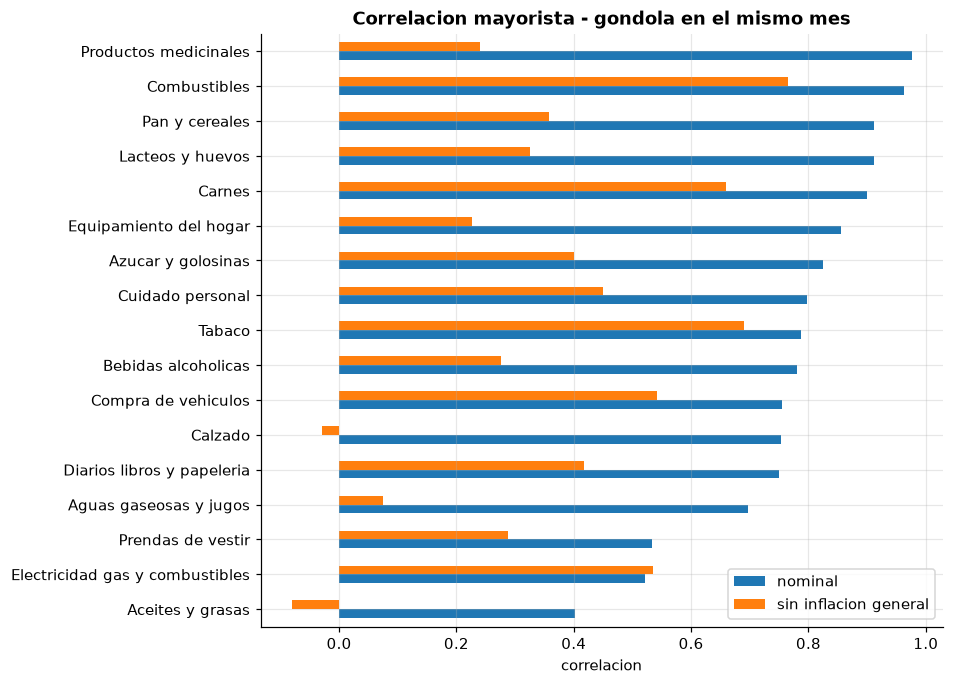

In [5]:
gondola = a.serie_por_rubro(precios, "gondola", "GBA")
industria = a.serie_por_rubro(precios, "industria")

nominal = a.correlacion_rezagos(gondola, industria)
relativa = a.correlacion_rezagos(
    a.relativa(gondola, general["GBA"]),
    a.relativa(industria, general["mayorista"]),
)

comparacion = (
    nominal[0]
    .rename("nominal")
    .to_frame()
    .join(relativa[0].rename("sin inflacion general"))
    .sort_values("nominal")
    .rename(index=nombres)
)
ax = comparacion.plot.barh(figsize=(8, 7))
ax.set_ylabel("")
ax.set_title("Correlacion mayorista - gondola en el mismo mes")
ax.set_xlabel("correlacion")
plt.show()

Mirando las variaciones tal cual, casi todo da arriba de 0.8. Pero eso es en buena parte la inflacion general: cuando todo sube 20% en un mes, el mayorista y la gondola de cualquier rubro suben juntos. Si a cada uno le resto la inflacion general (su propio nivel general, el del IPC y el del mayorista) y miro solo cuanto sube por encima o por debajo del resto, la foto cambia bastante. Productos medicinales por ejemplo pasa de 0.98 a 0.24.

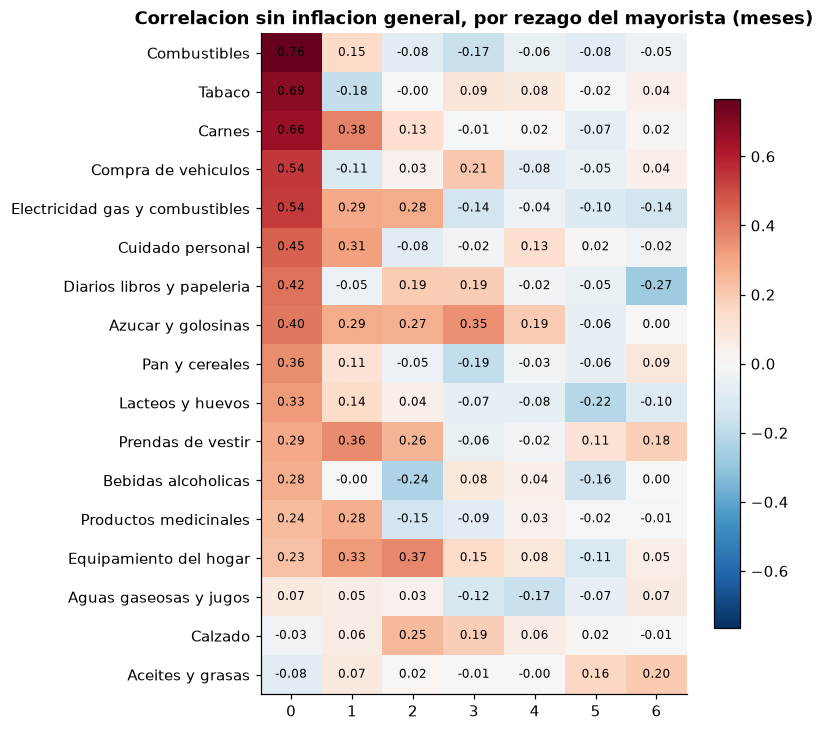

In [6]:
a.mapa_calor(
    relativa.sort_values(0, ascending=False).rename(index=nombres),
    "Correlacion sin inflacion general, por rezago del mayorista (meses)",
)
plt.show()

- Combustibles y tabaco se trasladan en el mismo mes. Son precios que fijan pocas empresas.
- Carnes: fuerte en el mes y todavia algo al mes siguiente, se reparte en unos dos meses.
- Equipamiento del hogar, prendas y calzado tienen el pico con 1 o 2 meses de rezago.
- Aceites y aguas, gaseosas y jugos casi no se relacionan. O la correspondencia entre los codigos es floja o el precio de gondola se forma por otro lado. Hay que revisarlos antes de sacar conclusiones.
- Electricidad, gas y combustibles del hogar (energia) da relacion, pero es tarifa regulada en las dos puntas: queda como contraste.

## 4. Estacionalidad

Promedio por mes de lo que sube cada rubro por encima de la inflacion general, en puntos porcentuales. Solo los 8 con mas diferencia entre meses.

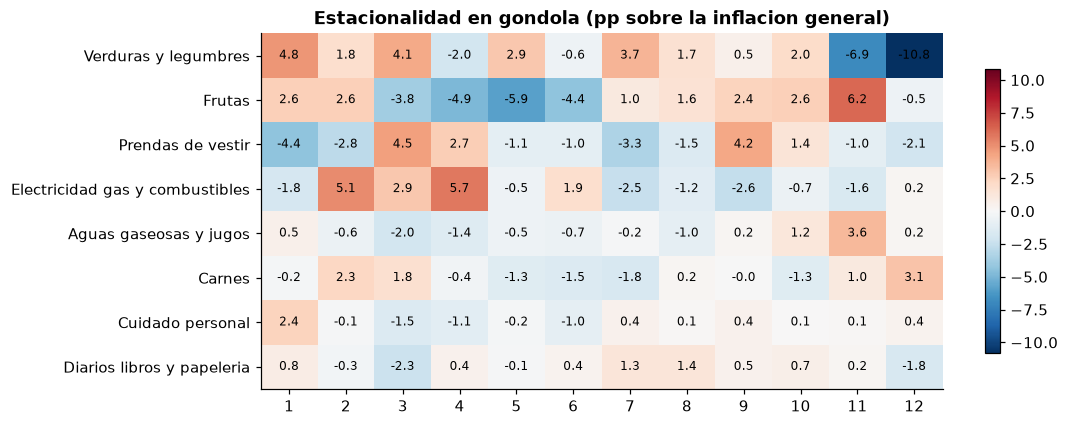

In [7]:
perfil = a.perfil_estacional(a.relativa(gondola, general["GBA"]))
amplitud = perfil.max(axis=1) - perfil.min(axis=1)
top = perfil.loc[amplitud.sort_values(ascending=False).index[:8]]

a.mapa_calor(
    top.rename(index=nombres),
    "Estacionalidad en gondola (pp sobre la inflacion general)",
    fmt="{:.1f}",
)
plt.show()

- Verduras bajan fuerte en noviembre y diciembre (la cosecha de verano). Frutas bajan de marzo a junio y suben en noviembre.
- Prendas suben en marzo y septiembre (cambio de temporada) y bajan en enero y febrero (liquidaciones).
- Energia salta en febrero y abril, pero eso no es estacionalidad del mercado: seguramente son los meses en que suelen entrar los aumentos de tarifas.
- El resto casi no tiene. En los modelos hace falta algo para la estacionalidad solo en un par de rubros.

## 5. Regiones

Cuantas veces se multiplico el precio en gondola desde dic-2016, dividido por lo que paso en GBA. Arriba de 1 subio mas que en GBA.

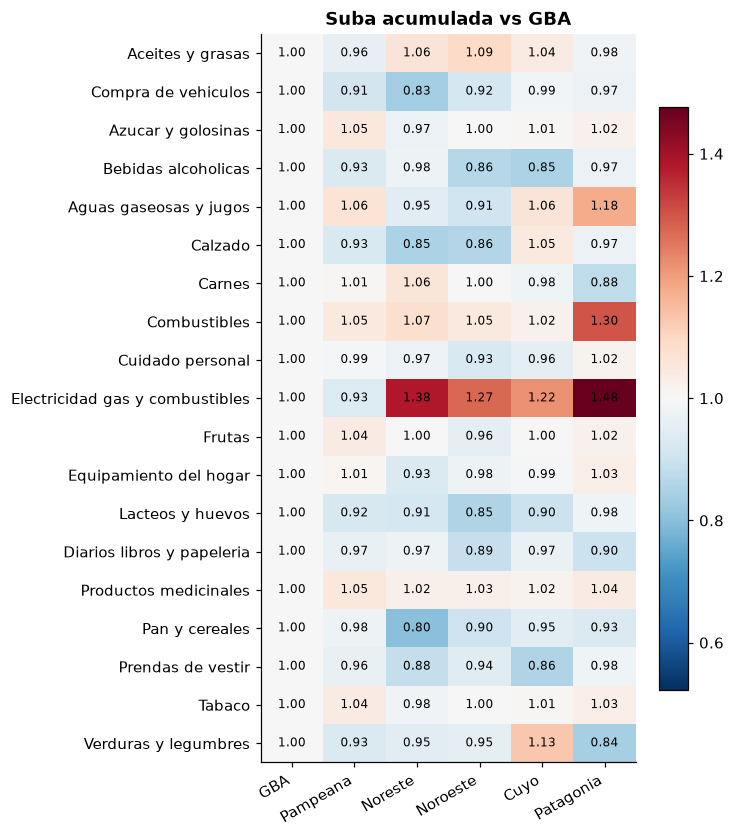

In [8]:
mult = a.multiplicador_regional(precios)
a.mapa_calor(
    mult.div(mult["GBA"], axis=0).rename(index=nombres),
    "Suba acumulada vs GBA",
    centro=1.0,
    rotar=30,
)
plt.show()

- Energia es la que mas cambia entre regiones: las tarifas dependen de decisiones regulatorias distintas en cada zona.
- Combustibles subio bastante mas en Patagonia y pan y cereales bastante menos en el Noreste.
- Fuera de eso las regiones se parecen. La pregunta para la fase 4 es si el mismo aumento mayorista llega igual de rapido a todas.

## Para la fase 4

- Trabajar con variaciones logaritmicas, no con niveles.
- Sacar la inflacion general (o controlarla en el modelo). Si no, se mide la inflacion y no el traslado.
- Probar por regimen: baja (2017, 2025-26), media (2018-21) y alta (2022-24).
- Rezagos de 0 a 3 meses alcanzan para casi todos los rubros.
- Estacionalidad solo en verduras, frutas y prendas (energia salta por los aumentos de tarifas).
- Revisar aceites y aguas, gaseosas y jugos antes de modelarlos.
- Faltan datos de la cuarentena de 2020 (restaurantes no entra, pero prendas y calzado si): el modelo tiene que tolerar huecos.